# Glove vs Fasttext vs Word2Vec vs Numberbatch

# Question 1


In [1]:
import numpy as np
import pandas as pd
import gensim.downloader as api

from pathlib import Path
from collections import Counter
from nltk.tokenize import TreebankWordTokenizer
from src.utils import load_datasets, PretrainedEmbeddings

In [2]:
train_df, val_df, test_df = load_datasets()

In [3]:
import urllib.request

def download_pretrained(option):
    """
    You can use this to download GloVe (or similar) model using urlib.
    It's fine to download it through other means, but don't unzip the file (the rest of the notebook can
    handle the file in its zipped format).

    This function returns the path which you can use for the loader class that follows.

    The function will skip the download if it detects the file in disk. If the file in disk is corrupted, you will have to delete the file first.
    """
    if option == "glove_50":
        if Path("glove.2024.wikigiga.50d.txt").is_file():
            destination = "glove.2024.wikigiga.50d.txt"
        else:
            destination = "glove.2024.wikigiga.50d.zip"
        dims = 50
        skip_first = False


    elif option == "fasttext":
        destination = "wiki-news-300d-1M.vec.zip"
        dims = 300
        skip_first = True
    
    elif option == "numberbatch":
        destination = "numberbatch-en-19.08.txt.gz"
        dims = 300
        skip_first = True

    else:
        raise ValueError(f"Unknown option: {option}")


    if not Path(destination).is_file():

        if option == "glove_50":
            urllib.request.urlretrieve("https://nlp.stanford.edu/data/wordvecs/glove.2024.wikigiga.50d.zip", destination)

        elif option == "fasttext":
            urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip", destination)

        elif option == "numberbatch":
            urllib.request.urlretrieve("https://conceptnet.s3.amazonaws.com/downloads/2019/numberbatch/numberbatch-en-19.08.txt.gz", destination)

        if not Path(destination).is_file():
            raise FileNotFoundError(f"Download failed: {destination}")

    return destination, dims, skip_first

**Embedding model proposals**

PAWS is English, and its sentences come from Wikipedia. GloVe 2024 is trained on Wikipedia and Gigaword so it matches our kind of text well. This also explains why it covers many Wikipedia names.



In [4]:
# Compare the vocab size of the models

models = {}

for option in ["glove_50", "fasttext", "word2vec", "numberbatch"]:

    if option != "word2vec":
        path, dims, skip_first = download_pretrained(option)

        models[option] = PretrainedEmbeddings(
            path, dims, skip_first_line=skip_first)

    else:
        models[option] = api.load("word2vec-google-news-300")

    if option == "word2vec":
        dims = models[option].vector_size
        vocab_size = len(models[option].key_to_index)
    else:
        dims = models[option].num_dims
        vocab_size = len(models[option].vocab)

    print(option, "dimensions:", dims, "vocabulary size:", vocab_size)

glove_50 dimensions: 50 vocabulary size: 1287614
fasttext dimensions: 300 vocabulary size: 830463
[==================================================] 100.0% 1662.8/1662.8MB downloaded
word2vec dimensions: 300 vocabulary size: 3000000
numberbatch dimensions: 300 vocabulary size: 516784


Word Tokenization for the dataset

In [5]:
tokenizer = TreebankWordTokenizer()

def tokenize(text):
    tokens = tokenizer.tokenize(text)

    return [
        token for token in tokens
        if any(char.isalnum() for char in token) # removes punctuation (because of word2vec mainly)
    ]

# Example tokenization
for sentence in train_df["sentence1"].head(5):
    print("Original:", sentence)
    print("Tokens:", tokenize(sentence), "\n")

Original: In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England through Scotland .
Tokens: ['In', 'Paris', 'in', 'October', '1560', 'he', 'secretly', 'met', 'the', 'English', 'ambassador', 'Nicolas', 'Throckmorton', 'asking', 'him', 'for', 'a', 'passport', 'to', 'return', 'to', 'England', 'through', 'Scotland'] 

Original: The NBA season of 1975 -- 76 was the 30th season of the National Basketball Association .
Tokens: ['The', 'NBA', 'season', 'of', '1975', '76', 'was', 'the', '30th', 'season', 'of', 'the', 'National', 'Basketball', 'Association'] 

Original: There are also specific discussions , public profile debates and project discussions .
Tokens: ['There', 'are', 'also', 'specific', 'discussions', 'public', 'profile', 'debates', 'and', 'project', 'discussions'] 

Original: When comparable rates of flow can be maintained , the results are high .
Tokens: ['When', 'comparable', 'rates', 'of', 'flow

In [6]:
sentences = pd.concat([
    train_df["sentence1"],
    train_df["sentence2"]
], ignore_index=True)

tokens = [
    token
    for sentence in sentences
    for token in tokenize(sentence)
]

print("Total tokens:", len(tokens))
print("Unique tokens:", len(set(tokens)))

Total tokens: 1824862
Unique tokens: 35294


**Compare vocabulary coverage for the embedding models**

In [7]:
def vocabulary_coverage(model, tokens):
    unique_tokens = set(tokens)

    covered_total_tokens = sum(token in model for token in tokens)
    covered_unique_tokens = sum(token in model for token in unique_tokens)

    total_token_coverage = covered_total_tokens / len(tokens)
    unique_token_coverage = covered_unique_tokens / len(unique_tokens)

    oov_words = [
        word for word in unique_tokens
        if word not in model
    ]

    return {
        "total_token_coverage": total_token_coverage,
        "unique_token_coverage": unique_token_coverage,
        "oov_words": oov_words
    }

In [8]:
results = {}

for name, model in models.items():
    results[name] = vocabulary_coverage(model, tokens)

coverage_df = pd.DataFrame({
    name: {
        "Total token coverage": result["total_token_coverage"] * 100,
        "Unique token coverage": result["unique_token_coverage"] * 100
    }
    for name, result in results.items()
}).T

display(coverage_df)

,Total token coverage,Unique token coverage
glove_50,98.926330,92.256474
fasttext,98.602305,91.134470
word2vec,83.471024,81.962940
numberbatch,90.979921,70.309401


**Missing token examples**

In [9]:
token_counts = Counter(tokens)

for name, result in results.items():
    print(f"{name}: Most frequent missing tokens")

    missing = sorted(
        result["oov_words"],
        key=lambda word: token_counts[word],
        reverse=True
    )

    for word in missing[:8]:
        print(word, token_counts[word])
    print()

glove_50: Most frequent missing tokens
½ 80
south-eastern 53
well-known 49
UPFA-SLFP 48
Leudesius 48
Shantih 48
Eoacmaeidae 48
Urechioiu 48

fasttext: Most frequent missing tokens
Lottiidae 80
UPFA-SLFP 48
Eletrônica 48
Leudesius 48
Aganbegyan 48
Eoacmaea 48
Eoacmaeidae 48
Urechioiu 48

word2vec: Most frequent missing tokens
and 65840
of 60405
a 35172
to 27754
's 5338
2011 1201
2015 1082
2010 954

numberbatch: Most frequent missing tokens
's 5338
2011 1201
2015 1082
2010 954
2012 942
2008 898
10 842
2013 806



Check which tokens Glove contains

In [15]:
glove = models["glove_50"]
for t in ["'s", "n't", "--", ",", ".", "1560", "well", "known", "-", "well-known", "south-eastern"]:
    print(f"{t:15} {t in glove}")


's              True
n't             True
--              True
,               True
.               True
1560            True
well            True
known           True
-               True
well-known      False
south-eastern   False


**Coverage with hyphen splitting**


In [18]:
def tokenize_split(text, model):
    """Like tokenize(), but splits hyphenated words the model doesn't know"""
    out = []
    for token in tokenizer.tokenize(text):
        if "-" in token and token not in model:
            out.extend(p for p in token.split("-") if p)
        else:
            out.append(token)
    return [t for t in out if any(c.isalnum() for c in t)]

split_rows = {}

for name, model in models.items():
    tokens_split = [t for sentence in sentences for t in tokenize_split(sentence, model)]
    r = vocabulary_coverage(model, tokens_split)
    split_rows[name] = {
        "Total token coverage": r["total_token_coverage"] * 100,
        "Unique token coverage": r["unique_token_coverage"] * 100,
    }

split_coverage_df = pd.DataFrame(split_rows).T
display(split_coverage_df)


,Total token coverage,Unique token coverage
glove_50,99.210569,94.892878
fasttext,98.683094,92.175948
word2vec,83.803075,84.802352
numberbatch,91.268534,72.762997


**Tokenization coherence with Glove**
- Glove is lowercased and our lookup lowercases too and Treebank splits like `'s` and `n't` also exist in Glove so our tokens match well.
- Main mismatch: hyphenated words like well-known are missing because Glove splits them and Treebank doesn't. Splitting hyphenated words a model doesn't know improves coverage for all models, for Glove it goes from 92.3% to 94.9% unique.
- The rest of the missing words are rare names and symbols, which is unavoidable.

**Conclusion Q1:** Glove has the best coverage (99.2% of tokens and 94.9% of unique tokens) while being 6× smaller than fastText and its tokenization matches ours well.


# Question 2

Cosine similarity of different word types

In [10]:
def get_vector(word, model, name):
    if name == "word2vec":
        if word in model:
            return model[word]
        return None

    if word in model:
        return model.embed_word(word)
    return None


def cos_similarity(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


def word_similarity(word1, word2, model, name):
    u = get_vector(word1, model, name)
    v = get_vector(word2, model, name)

    if u is None or v is None:
        return np.nan

    return cos_similarity(u, v)

In [11]:
word_pairs = [
    ("car", "automobile", "Synonyms"),
    ("city", "town", "Synonyms"),
    ("car", "banana", "Unrelated"),
    ("city", "elephant", "Unrelated"),
    ("dog", "cat", "Related concepts"),
    ("king", "queen", "Related concepts"),
    ("increase", "decrease", "Antonyms"),
    ("before", "after", "Antonyms"),
]

rows = []

for word1, word2, category in word_pairs:
    row = {
        "Word 1": word1,
        "Word 2": word2,
        "Category": category
    }

    for name, model in models.items():
        row[name] = word_similarity(word1, word2, model, name)

    rows.append(row)

similarity_df = pd.DataFrame(rows)
display(similarity_df.round(3))

,Word 1,Word 2,Category,glove_50,fasttext,word2vec,numberbatch
0,car,automobile,Synonyms,0.715,0.767,0.584,0.883
1,city,town,Synonyms,0.880,0.799,0.672,0.686
2,car,banana,Unrelated,0.320,0.391,0.112,-0.005
3,city,elephant,Unrelated,0.385,0.384,0.104,0.013
4,dog,cat,Related concepts,0.941,0.687,0.761,0.667
5,king,queen,Related concepts,0.810,0.667,0.651,0.837
6,increase,decrease,Antonyms,0.907,0.923,0.837,0.793
7,before,after,Antonyms,0.965,0.784,0.758,0.750


Closest words to a certain word

In [22]:
def nearest_neighbors(word, model, name, k=10):
    if name == "word2vec":
        if word not in model:
            word = word.lower()

        if word not in model:
            return []

        return model.most_similar(word, topn=k)

    if word not in model:
        return []

    query = model.embed_word(word)

    E = model.vectors

    query_norm = np.linalg.norm(query)
    norms = np.linalg.norm(E, axis=1)

    scores = (E @ query) / (np.maximum(norms * query_norm, 1e-12))

    # Exclude special tokens and the query word
    scores[:2] = -np.inf
    scores[model.index(word)] = -np.inf

    top_indices = np.argsort(scores)[-k:][::-1]

    return [(model.word(i), float(scores[i])) for i in top_indices]

test_words = ["car", "city", "king", "increase", "in", "from"]

for word in test_words:
    print(f"\nWORD: {word}")

    for name, model in models.items():
        neighbors = nearest_neighbors(word, model, name, k=5)

        print(f"{name}: {[w for w, score in neighbors]}")


WORD: car
glove_50: ['truck', 'vehicle', 'cars', 'driving', 'driver']
fasttext: ['cars', 'automobile', 'vehicle', 'truck', 'suv']
word2vec: ['vehicle', 'cars', 'SUV', 'minivan', 'truck']
numberbatch: ['go_for_spin', 'lose_wheel', 'enter_garage', 'sunbeam_automobile', 'morgan_automobile']

WORD: city
glove_50: ['where', 'cities', 'town', 'downtown', 'outside']
fasttext: ['town', 'cities', 'downtown', 'towns', 'suburb']
word2vec: ['citys', 'mayor', 'town', 'municipality', 'municipal']
numberbatch: ['relizane', 'port_moody', 'minicity', 'many_buildings', 'microcity']

WORD: king
glove_50: ['prince', 'queen', 'brother', 'grandson', 'throne']
fasttext: ['kings', 'queen', 'alveda', 'burger', 'king-']
word2vec: ['kings', 'queen', 'monarch', 'crown_prince', 'prince']
numberbatch: ['king_of_france', 'king_of_germans', 'male_monarch', 'nonking', 'riley_b_king']

WORD: increase
glove_50: ['increased', 'increases', 'increasing', 'decrease', 'reduce']
fasttext: ['decrease', 'reduce', 'increases', 

**Which words get substituted between the two sentences in PAWS?**

We find pairs where exactly one word differs between sentence1 and sentence2 (ignoring order) and check how similar the models consider these words.


In [19]:
from collections import Counter

subs = Counter()
for s1, s2, label in zip(train_df["sentence1"], train_df["sentence2"], train_df["label"]):
    t1 = Counter(w.lower() for w in tokenize(s1))
    t2 = Counter(w.lower() for w in tokenize(s2))
    only1, only2 = list((t1 - t2).elements()), list((t2 - t1).elements())
    if len(only1) == 1 and len(only2) == 1:
        subs[(only1[0], only2[0], label)] += 1

n_total = sum(subs.values())
print(f"Pairs that differ in exactly one word: {n_total} of {len(train_df)}")

rows = []
for (w1, w2, label), count in subs.most_common(15):
    rows.append({
        "Word 1": w1, "Word 2": w2, "Label": label, "Count": count,
        "glove_50": word_similarity(w1, w2, models["glove_50"], "glove_50"),
        "fasttext": word_similarity(w1, w2, models["fasttext"], "fasttext"),
    })
display(pd.DataFrame(rows).round(3))


Pairs that differ in exactly one word: 11935 of 49401


,Word 1,Word 2,Label,Count,glove_50,fasttext
0,in,at,0,48,0.853,0.695
1,at,in,1,46,0.853,0.695
2,at,in,0,40,0.853,0.695
3,in,at,1,35,0.853,0.695
4,from,of,0,33,0.880,0.644
5,of,from,0,33,0.880,0.644
6,from,of,1,32,0.880,0.644
7,in,of,0,31,0.917,0.707
8,of,in,1,30,0.917,0.707
9,in,on,0,28,0.910,0.659


About 24% of pairs (11,935 of 49,401) differ in exactly one word. The substituted words are almost all function words (in/at, from/of, the/a), and the same substitution occurs about equally often in both classes. So the word itself doesn't decide the label, the sentence structure does. Glove rates these prepositions as very similar (0.83–0.92).


Average embedding (shows formally that word vectors dont encode positions/context)

In [13]:
def average_embedding(sentence, model, name):
    vectors = [get_vector(token, model, name) for token in tokenize(sentence)]

    if not vectors:
        return None

    return np.mean(vectors, axis=0)


sentence1 = "The dog chased the man."
sentence2 = "The man chased the dog."

for name, model in models.items():
    v1 = average_embedding(sentence1, model, name)
    v2 = average_embedding(sentence2, model, name)

    print(name, cos_similarity(v1, v2))

glove_50 0.99999994
fasttext 1.0000001
word2vec 0.99999994
numberbatch 1.0


**Can averaged embeddings separate paraphrases from non-paraphrases on PAWS?**

For each training pair we average the word vectors of both sentences and compute the cosine between them, for Glove and fastText.


glove_50: mean cosine paraphrase = 0.9979, non-paraphrase = 0.9979, AUC = 0.484
fasttext: mean cosine paraphrase = 0.9952, non-paraphrase = 0.9950, AUC = 0.491


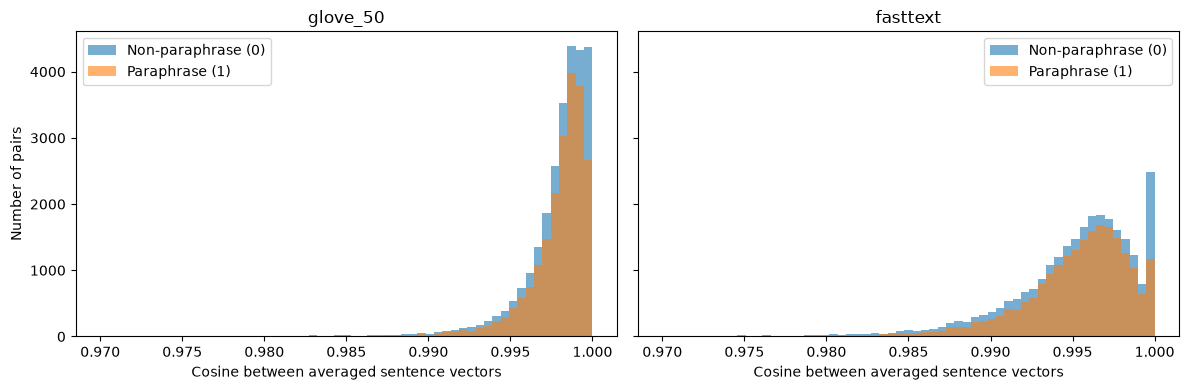

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

def mean_vector(sentence, model):
    vecs = [model.embed_word(t) for t in tokenize_split(sentence, model) if t in model]
    return np.mean(vecs, axis=0) if vecs else None

def pair_cosines(df, model):
    cos = []
    for s1, s2 in zip(df["sentence1"], df["sentence2"]):
        u, v = mean_vector(s1, model), mean_vector(s2, model)
        cos.append(cos_similarity(u, v) if u is not None and v is not None else np.nan)
    return np.array(cos)

labels = train_df["label"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, name in zip(axes, ["glove_50", "fasttext"]):
    cos = pair_cosines(train_df, models[name])
    ok = ~np.isnan(cos)

    print(f"{name}: mean cosine paraphrase = {cos[ok & (labels == 1)].mean():.4f}, "
          f"non-paraphrase = {cos[ok & (labels == 0)].mean():.4f}, "
          f"AUC = {roc_auc_score(labels[ok], cos[ok]):.3f}")

    bins = np.linspace(0.97, 1.0, 60)

    ax.hist(cos[ok & (labels == 0)], bins=bins, alpha=0.6, label="Non-paraphrase (0)")
    ax.hist(cos[ok & (labels == 1)], bins=bins, alpha=0.6, label="Paraphrase (1)")
    ax.set_title(name)
    ax.set_xlabel("Cosine between averaged sentence vectors")
    ax.legend()

axes[0].set_ylabel("Number of pairs")
plt.tight_layout()
plt.show()


**Conclusion Q2**

What GloVe captures well:
- Synonyms and related words get high similarity (city/town 0.88, dog/cat 0.94) and unrelated words low similarity (car/banana 0.32).
- Content words get meaningful nearest neighbours (car and truck, vehicle; king and prince, queen).


Overall limitations/findings:
- Word vectors can't encode the context of the sentence and position
- Antonym vectors are similar for all models except Numberbatch (could be problematic for PAWS specifically)
- Function words like "in" and "from" have vague vectors, their closest words are other prepositions and even punctuation
- Word2Vec model struggles with stopwords and numbers even after filtering for punctuation
- Numberbatch struggles mostly with numbers
- Every word has one vector, so words with multiple meanings (like "bank", river or money) get one mixed vector no matter the context
- Embeddings learn biases from their training text 



PAWS specific findings:
- When pairs differ in one word it's almost always a function word (in/at, from/of) and the same swap happens in both classes, so the word itself doesn't decide the label
- Averaged embeddings can't separate paraphrases from non-paraphrases at all, the cosine is 0.9979 for both classes with Glove and the AUC is 0.484 (Glove) and 0.491 (fastText), so basically guessing
- Pairs with the same words in a different order get cosine 1.0 and most of these are non-paraphrases
- So we need a model that sees word order, also fastText has the same problem so it's not about which embedding we use
- On PAWS, Glove and fastText perform the same, so our choice for Glove is based on coverage and model size


